Question 1:

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# If your file has multiple sheets:
df = pd.read_excel('evanston_restaurant_data.xlsx', sheet_name='Reviews')
df_res = pd.read_excel('evanston_restaurant_data.xlsx', sheet_name='Restaurants')


In [4]:

# Check for missing values
missing_counts = df.isnull().sum()
missing_columns = missing_counts[missing_counts > 0]
print(missing_columns)

Review Text                     574
Birth Year                        2
Marital Status                   35
Has Children?                    38
Vegetarian?                    1405
Weight (lb)                      97
Height (cm)                      54
Average Amount Spent              1
Preferred Mode of Transport       4
dtype: int64


In [5]:
# 1. Text feature
df['Review Text'] = df['Review Text'].fillna('')

# 2. Categorical features → “Unknown” bucket
for col in ['Vegetarian?',
            'Marital Status',
            'Has Children?',
            'Preferred Mode of Transport']:
    df[col] = df[col].fillna('Unknown')

# 3. Numeric features → median imputation + missing‐flag
for col in ['Birth Year',
            'Weight (lb)',
            'Height (cm)']:
    df[f'{col}_missing'] = df[col].isna().astype(int)
    df[col] = df[col].fillna(df[col].median())

# Mode imputation for 'Average Amount Spent'
mode_value = df['Average Amount Spent'].mode()[0]
df['Average Amount Spent'] = df['Average Amount Spent'].fillna(mode_value)



Question 2

<module 'matplotlib.pyplot' from '/Users/chan/miniconda3/envs/stat415_hw1_env/lib/python3.11/site-packages/matplotlib/pyplot.py'>

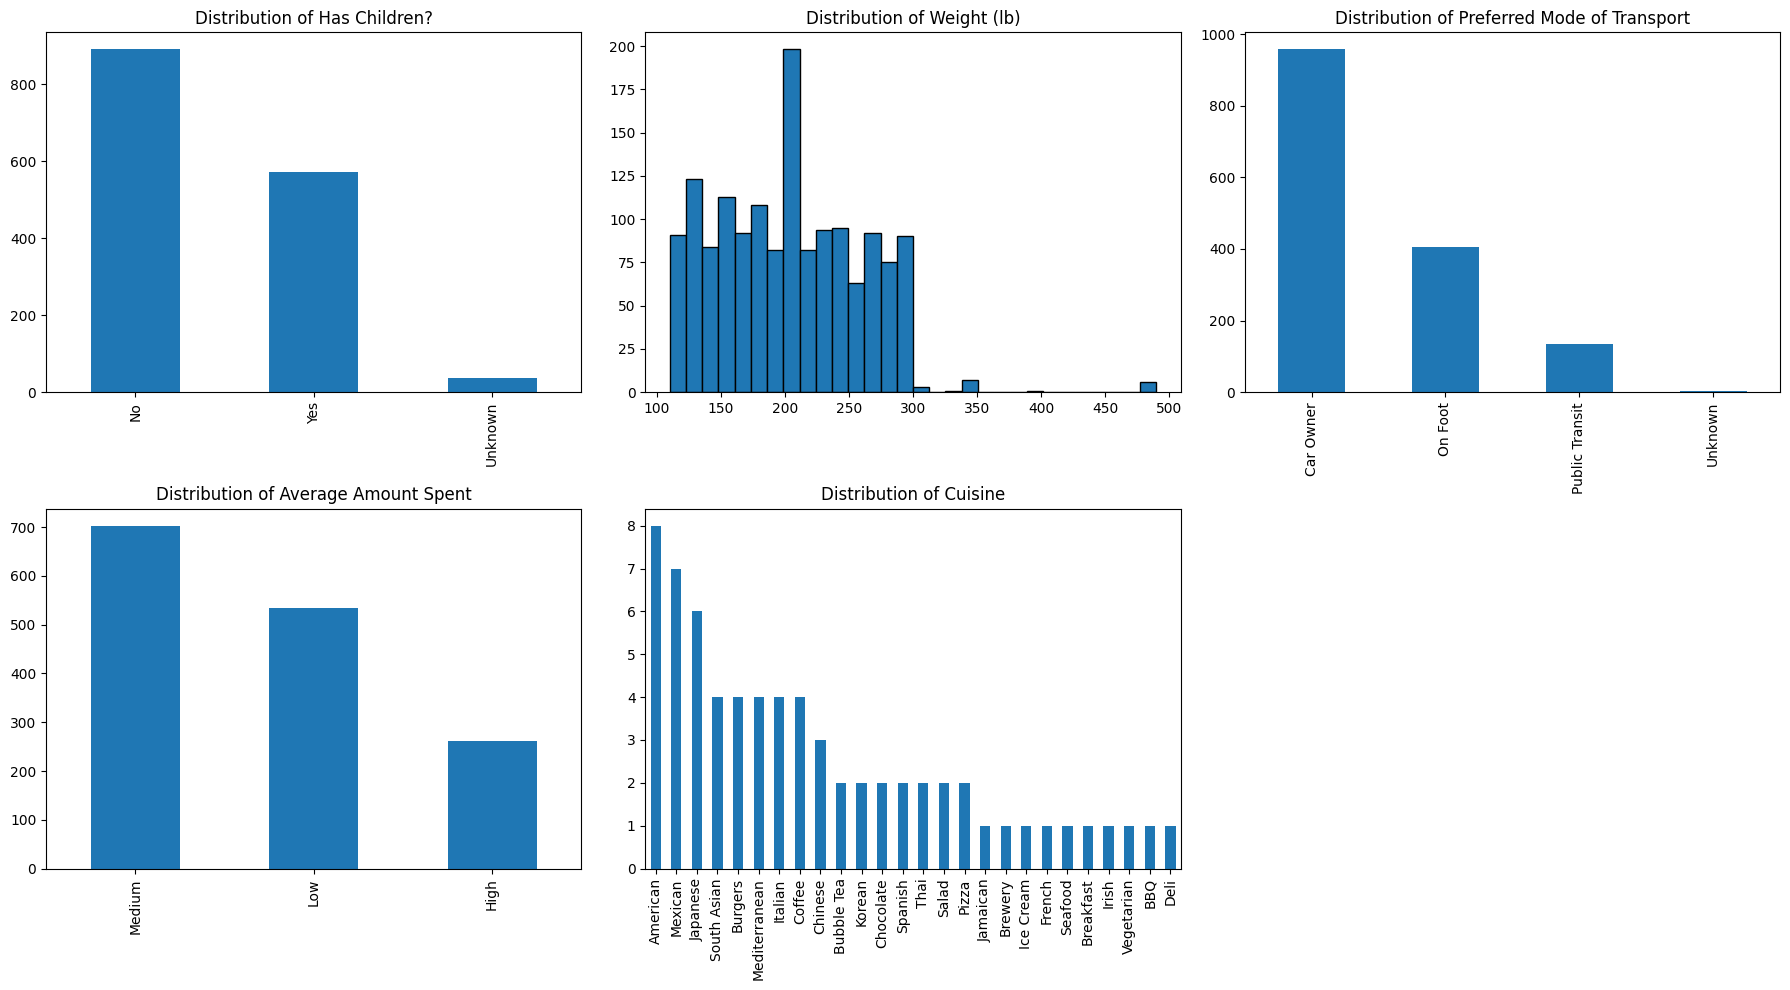

In [6]:
# Columns to plot from df
columns_to_plot_df = [
    'Has Children?',
 #   'Vegetarian?',
    'Weight (lb)',
    'Preferred Mode of Transport',
    'Average Amount Spent'
]

# Column to plot from df_res
columns_to_plot_df_res = ['Cuisine']  # we'll double-check spelling separately!

# --- Combine all columns ---
all_columns = columns_to_plot_df + ['Cuisine']  # merging the list

# --- Set up grid ---
n_cols = 3  # number of plots per row
n_rows = (len(all_columns) + n_cols - 1) // n_cols  # auto-calculate needed rows

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))
axes = axes.flatten()  # easy to index even if only 1 row

# --- Plot each column ---
for idx, col in enumerate(all_columns):
    ax = axes[idx]
    if col == 'Cuisine':
        # Plot from df_res
        if col in df_res.columns:
            df_res[col].value_counts(dropna=False).plot(kind='bar', ax=ax)
        else:
            ax.text(0.5, 0.5, 'Column not found', ha='center', va='center')
            ax.set_title('Cuisine')
    else:
        # Plot from df
        if df[col].dtype == 'object' or df[col].nunique() < 20:
            df[col].value_counts(dropna=False).plot(kind='bar', ax=ax)
        else:
            df[col].plot(kind='hist', bins=30, edgecolor='black', ax=ax)
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel('')
    ax.set_ylabel('')

# --- Remove any empty plots ---
for j in range(idx + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt


Question 3:

In [7]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering

# ——— 1. select and one-hot encode demographic features ———
demo_cols = [
    'Marital Status', 'Has Children?', 'Vegetarian?',
    'Preferred Mode of Transport', 'Average Amount Spent', 'Northwestern Student?'
]
X = df[demo_cols].fillna('Unknown')
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
X_enc = encoder.fit_transform(X)


# attach back as DataFrame for reference
X_enc_df = pd.DataFrame(X_enc, columns=encoder.get_feature_names_out(demo_cols), index=df.index)

# ——— helper to compute and display cluster summaries ———
def summarize_clusters(labels, name):
    df[f'{name}_cluster'] = labels
    summary = (
        df
        .groupby(f'{name}_cluster')['Rating']
        .agg(['count', 'mean'])
        .rename(columns={'count':'n_users', 'mean':'avg_rating'})
        .reset_index()
    )
    print(f"\n### {name} clustering summary")
    display(summary)

# ——— 2a. K-Means ———
kmeans = KMeans(n_clusters=4, random_state=0)
summarize_clusters(kmeans.fit_predict(X_enc), 'KMeans')

# ——— 2b. DBSCAN ———
db = DBSCAN(eps=0.5, min_samples=10, metric='euclidean')
summarize_clusters(db.fit_predict(X_enc), 'DBSCAN')

# ——— 2c. Agglomerative ———
agg = AgglomerativeClustering(n_clusters=4, linkage='ward')
summarize_clusters(agg.fit_predict(X_enc), 'Agglo')



### KMeans clustering summary


,KMeans_cluster,n_users,avg_rating
0,0,158,4.018987
1,1,540,3.592593
2,2,411,3.807786
3,3,391,3.780051



### DBSCAN clustering summary


,DBSCAN_cluster,n_users,avg_rating
0,-1,176,3.823864
1,0,133,3.992481
2,1,82,4.000000
3,2,22,3.409091
4,3,63,3.841270
5,4,22,2.863636
6,5,67,4.000000
7,6,103,3.368932
8,7,10,3.900000
9,8,154,3.948052



### Agglo clustering summary


,Agglo_cluster,n_users,avg_rating
0,0,627,3.558214
1,1,321,4.049844
2,2,235,3.923404
3,3,317,3.675079


Question 4:

In [8]:
# 1. Calculate average rating per restaurant
restaurant_avg = df.groupby('Restaurant Name')['Rating'].mean()

# 2. Find the restaurant with the highest average rating
top_restaurant = restaurant_avg.idxmax()
top_score = restaurant_avg.max()

# 3. Calculate overall average rating
overall_avg = df['Rating'].mean()

# 4. Display results
print(f"Restaurant with highest average rating: {top_restaurant}")
print(f"Highest restaurant average rating: {top_score:.2f}")
print(f"Overall average rating: {overall_avg:.2f}")
print(f"Difference: {top_score - overall_avg:.2f}")

Restaurant with highest average rating: Evanston Games & Cafe
Highest restaurant average rating: 5.00
Overall average rating: 3.75
Difference: 1.25


In [9]:
# 4. Calculate number of reviews per restaurant
review_counts = df['Restaurant Name'].value_counts()

# 5. Find restaurant with the most reviews
most_reviewed_restaurant = review_counts.idxmax()
most_reviews = review_counts.max()

# 6. Calculate median number of reviews
median_reviews = review_counts.median()

print(f"Restaurant with most reviews: {most_reviewed_restaurant}")
print(f"Number of reviews for most-reviewed restaurant: {most_reviews}")
print(f"Median number of reviews across all restaurants: {median_reviews}")
print(f"Difference in number of reviews: {most_reviews - median_reviews}")

Restaurant with most reviews: Campagnola
Number of reviews for most-reviewed restaurant: 48
Median number of reviews across all restaurants: 22.0
Difference in number of reviews: 26.0


Question 5:

In [10]:
# 1. Merge restaurant info into the review dataset
merged_df = pd.merge(df, df_res, on='Restaurant Name', how='left')

# 2. Calculate popularity based on number of reviews
popularity = (
    merged_df.groupby(['Restaurant Name', 'Cuisine']) # group reviews by cuisine (redundant) and by restaurant
    .size() # count how many reviews each restaurant has
    .reset_index(name='num_reviews') # create df with three cols: cuisine, restaurant, and tot num of reviews
)

# 3. Recommendation function (based on number of reviews)
def recommend_restaurants(cuisine_type, top_n=5):
    filtered = popularity[popularity['Cuisine'].str.contains(cuisine_type, case=False, na=False)]
    top_restaurants = filtered.sort_values('num_reviews', ascending=False).head(top_n)
    top_restaurants['Cuisine Type'] = cuisine_type.title()  # Add cuisine label for clarity
    return top_restaurants[['Cuisine Type', 'Restaurant Name', 'num_reviews']]

# 4. Generate all recommendations and combine into one table
recs_spanish = recommend_restaurants('Spanish')
recs_chinese = recommend_restaurants('Chinese')
recs_mexican = recommend_restaurants('Mexican')
recs_coffee = recommend_restaurants('Coffee')

# 5. Combine into a single clean table
final_recommendations = pd.concat([recs_spanish, recs_chinese, recs_mexican, recs_coffee]).reset_index(drop=True)

# 6. Display clean final table
display(final_recommendations)

,Cuisine Type,Restaurant Name,num_reviews
0,Spanish,Tapas Barcelona,29
1,Spanish,5411 Empanadas,28
2,Chinese,Peppercorns Kitchen,33
3,Chinese,Joy Yee Noodle,31
4,Chinese,Lao Sze Chuan,24
5,Mexican,Chipotle,41
6,Mexican,Taco Diablo,37
7,Mexican,Zentli,17
8,Mexican,Fridas,13
9,Mexican,Guzman y Gomez,10


Question 6:

In [11]:
# final_recommendations_copy = final_recommendations.copy()

# mu_s = overall_avg
# N_mu = review_counts.mean()
# # create lookup table for mean rating of each restaurant
# restaurant_stats = (
#     df
#     .groupby('Restaurant Name')['Rating']
#     .agg(['mean', 'count'])
#     .reset_index()
#     .rename(columns={'mean': 'mu_p', 'count': 'N_p'})
# )

# # Rank by number of reviews (higher num_reviews = better rank)
# popularity['rank_num_reviews'] = popularity['num_reviews'].rank(ascending=False)

# # Compute the new popularity estimate
# restaurant_stats['popularity_est'] = (N_mu * mu_s + restaurant_stats['N_p'] * restaurant_stats['mu_p']) / (restaurant_stats['N_p'] + N_mu)

# # Rank by popularity_est (higher popularity_est = better rank)
# restaurant_stats['rank_popularity_est'] = restaurant_stats['popularity_est'].rank(ascending=False)

# # Calculate difference in rankings
# difference_df = pd.DataFrame({
#     'Restaurant Name': restaurant_stats['Restaurant Name'],
#     'difference_in_rank': restaurant_stats['rank_popularity_est'] - popularity['rank_num_reviews']
# })

# # Find the restaurant with biggest increase (most positive difference)
# idx_max = difference_df['difference_in_rank'].idxmax()
# restaurant_max = difference_df.loc[idx_max, 'Restaurant Name']
# max_diff = difference_df.loc[idx_max, 'difference_in_rank']

# # Find the restaurant with biggest decrease (most negative difference)
# idx_min = difference_df['difference_in_rank'].idxmin()
# restaurant_min = difference_df.loc[idx_min, 'Restaurant Name']
# min_diff = difference_df.loc[idx_min, 'difference_in_rank']

# # Print results
# print(f"The restaurant with the biggest increase in ranking: {restaurant_max}")
# print(f"The max difference is {max_diff}")
# print(f"The restaurant with the biggest decrease in ranking: {restaurant_min}")
# print(f"The min difference is {min_diff}")


▲ Most benefited: Clare's Korner  (Δ = +2.618)
▼ Most hurt     : Evanston Games & Cafe (Δ = -1.196)



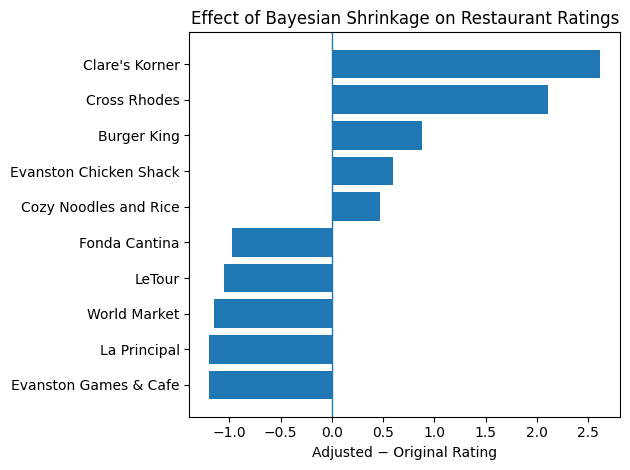

In [12]:
# --- 1. core statistics ---------------------------------------------------
mu_s = df['Rating'].mean()

stats = (
    df.groupby('Restaurant Name')['Rating']
      .agg(['mean', 'count'])
      .rename(columns={'mean':'mu_p', 'count':'N_p'})
      .reset_index()
)

N_mu = stats['N_p'].mean()
stats['shrink_est'] = (N_mu*mu_s + stats['N_p']*stats['mu_p']) / (stats['N_p'] + N_mu)
stats['diff']       = stats['shrink_est'] - stats['mu_p']          # + = benefited

# --- 2. biggest winners / losers -----------------------------------------
best  = stats.loc[stats['diff'].idxmax()]
worst = stats.loc[stats['diff'].idxmin()]

print(f"▲ Most benefited: {best['Restaurant Name']}  (Δ = {best['diff']:+.3f})")
print(f"▼ Most hurt     : {worst['Restaurant Name']} (Δ = {worst['diff']:+.3f})\n")

# --- 3. visualise ---------------------------------------------------------
top_pos = stats.nlargest(5, 'diff')
top_neg = stats.nsmallest(5, 'diff')
changes = pd.concat([top_neg, top_pos]).sort_values('diff')

plt.figure()
plt.barh(changes['Restaurant Name'], changes['diff'])
plt.axvline(0, lw=1)
plt.title('Effect of Bayesian Shrinkage on Restaurant Ratings')
plt.xlabel('Adjusted − Original Rating')
plt.tight_layout()
plt.show()


Question 7:

In [13]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import pairwise_distances
import numpy as np
from sklearn.preprocessing import StandardScaler

# ——— 1. Prepare the data ———
categorical_cols = ['Cuisine', 'Open After 8pm?']
X_cat = df_res[categorical_cols]
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
X_encoded = encoder.fit_transform(X_cat)

# prepare continuous variables
continuous_cols=['Latitude', 'Longitude', 'Average Cost']

for col in continuous_cols:
    df_res[col] = pd.to_numeric(df_res[col], errors='coerce')
X_cont = df_res[continuous_cols].fillna(df_res[continuous_cols].mean())

# Scale continuous variables
scaler = StandardScaler()
X_cont = scaler.fit_transform(X_cont)

# combine them into one 
X_combined = np.hstack((X_encoded, X_cont))
display(X_combined)

# get restaurant names
restaurant_names = df_res['Restaurant Name']

# ——— 2. Compute Euclidean distances ———
euclid_mat = pairwise_distances(X_combined, metric='euclidean')
euclid_df = pd.DataFrame(euclid_mat, index=restaurant_names, columns=restaurant_names)


array([[ 0.        ,  0.        ,  0.        , ...,  0.09555165,
        -0.25371604,  0.0415174 ],
       [ 0.        ,  0.        ,  0.        , ...,  0.33878777,
        -0.25372654,  0.0415174 ],
       [ 0.        ,  0.        ,  0.        , ...,  0.17646725,
        -0.25378407, -0.81771218],
       ...,
       [ 0.        ,  0.        ,  0.        , ...,  0.40054266,
         3.99799924,  0.0415174 ],
       [ 0.        ,  0.        ,  0.        , ...,  2.58491125,
         3.99856659, -0.81771218],
       [ 0.        ,  0.        ,  0.        , ..., -0.06451646,
         3.99794105,  0.0415174 ]], shape=(68, 31))

Question 8:

In [14]:

# ——— 3. Compute Cosine distances → Cosine similarities ———
cos_dist_mat = pairwise_distances(X_combined, metric='cosine')
cos_dist_df  = pd.DataFrame(cos_dist_mat,  index=restaurant_names, columns=restaurant_names)

# Cosine similarity = 1 − cosine distance
cos_sim_df = 1 - cos_dist_df

# ——— 4. Extract and print the two pairs ———
pairs = [
    ('Peppercorns Kitchen', 'Epic Burger'),
    ('Peppercorns Kitchen', 'Lao Sze Chuan')
]

for a, b in pairs:
    e = euclid_df.loc[a, b]
    s = cos_sim_df.loc[a, b]
    print(f"Between {a!r} and {b!r}:")
    print(f"  • Euclidean distance     = {e:.4f}")
    print(f"  • Cosine similarity      = {s:.4f}")
    print()


Between 'Peppercorns Kitchen' and 'Epic Burger':
  • Euclidean distance     = 1.4287
  • Cosine similarity      = 0.5160

Between 'Peppercorns Kitchen' and 'Lao Sze Chuan':
  • Euclidean distance     = 0.2620
  • Cosine similarity      = 0.9842



Question 9: 

Favorite restaurant for Willie Jacobsen: 'Jimmy Johns'



,Restaurant Name,Distance
0,Clarkes Off Campus,0.939899
1,Hecky's BBQ,0.970080
2,Philz Coffee,1.463647
3,Edzo's Burger Shop,1.484039
4,Pâtisserie Coralie,1.488881
5,Evanston Chicken Shack,1.489911
6,Le Peep,1.659451
7,Fridas,1.666986
8,Prairie Moon,1.678484
9,Mumbai Indian Grill,2.000114


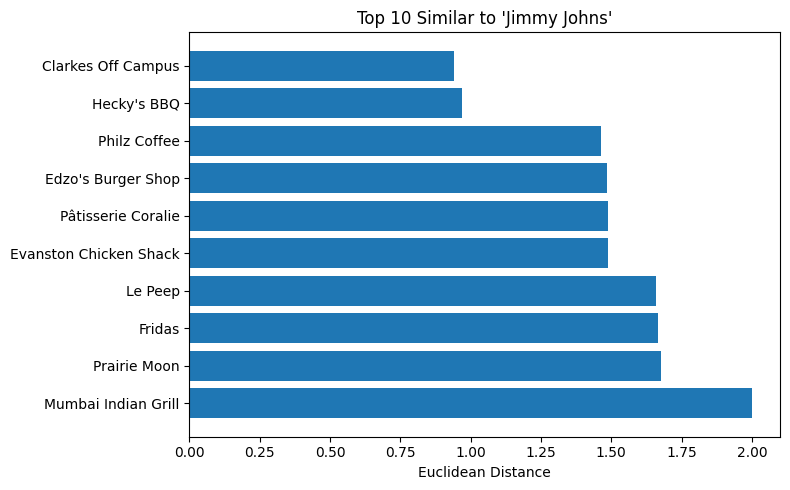

In [15]:
# ——— Assumes you already have ———
# df: DataFrame of reviews with columns ['Reviewer Name','Restaurant Name','Rating']
# euclid_df: DataFrame of pairwise Euclidean distances
#            indexed & columned by restaurant name

def get_favorite_restaurant(user_name: str, reviews: pd.DataFrame) -> str:
    """Return the restaurant with the highest rating for a given user."""
    user_rev = reviews[reviews['Reviewer Name'] == user_name]
    if user_rev.empty:
        raise ValueError(f"No reviews found for user {user_name!r}")
    # pick the one with max rating; break ties by count or first occurrence
    top_rating = user_rev['Rating'].max()
    fav = user_rev[user_rev['Rating'] == top_rating]['Restaurant Name'].iloc[0]
    return fav

def recommend_similar(favorite: str,
                      distances: pd.DataFrame,
                      top_n: int = 10) -> pd.Series:
    """Return the top_n closest restaurants to `favorite`."""
    if favorite not in distances.index:
        raise KeyError(f"{favorite!r} not in distance matrix.")
    # distances to all others
    dists = distances.loc[favorite].drop(favorite)
    return dists.nsmallest(top_n)

# ——— Run for Willie Jacobsen ———
user = 'Willie Jacobsen'
fav_rest = get_favorite_restaurant(user, df)

print(f"Favorite restaurant for {user}: {fav_rest!r}\n")

top10 = recommend_similar(fav_rest, euclid_df, top_n=10)

# ——— Display as table ———
results_df = top10.rename('Euclidean Distance').reset_index()
results_df.columns = ['Restaurant Name','Distance']
display(results_df)

# ——— Display as bar chart ———
plt.figure(figsize=(8,5))
plt.barh(results_df['Restaurant Name'], results_df['Distance'])
plt.gca().invert_yaxis()
plt.xlabel('Euclidean Distance')
plt.title(f"Top 10 Similar to {fav_rest!r}")
plt.tight_layout()
plt.show()


Question 10:

In [27]:
# 1. True average ratings
restaurant_stats = (
    df.groupby('Restaurant Name')['Rating']
    .mean()
    .rename('avg_rating')
)

# 2. Only use queries that exist in the distance matrix
queries = [r for r in restaurant_stats.index if r in euclid_df.index]

rows = []

for q in queries:
    # Top-10 closest under Euclidean (filter neighbors too)
    rec_e = [r for r in euclid_df.loc[q].drop(q).nsmallest(10).index if r in restaurant_stats.index]

    # Top-10 closest under Cosine (filter neighbors too)
    rec_c = [r for r in cos_sim_df.loc[q].drop(q).nlargest(10).index if r in restaurant_stats.index]

    # Calculate mean neighbor ratings
    euclid_avg_rating = restaurant_stats.loc[rec_e].mean()
    cosine_avg_rating = restaurant_stats.loc[rec_c].mean()

    rows.append({
        'query': q,
        'euclid_avg': euclid_avg_rating,
        'cosine_avg': cosine_avg_rating
    })

# 3. Compile result
comp = pd.DataFrame(rows)
comp['delta'] = comp['cosine_avg'] - comp['euclid_avg']
comp.loc['Overall'] = {
    'query': 'Overall Mean',
    'euclid_avg': comp['euclid_avg'].mean(),
    'cosine_avg': comp['cosine_avg'].mean(),
    'delta': comp['delta'].mean()
}

# 4. Display final result
display(comp[['query', 'euclid_avg', 'cosine_avg', 'delta']])

print(comp['delta'].mean())

,query,euclid_avg,cosine_avg,delta
0,5411 Empanadas,3.763609,3.745752,-0.017857
1,Alcove,4.025398,3.871231,-0.154167
2,Barn Steakhouse,3.866334,4.005223,0.138889
3,Brothers K Coffeehouse,3.561051,3.666933,0.105882
4,Burger King,3.917445,3.433227,-0.484218
...,...,...,...,...
62,Trattoria DOC,3.463709,3.495116,0.031407
63,Trattoria Demi,4.029921,4.011299,-0.018622
64,Union Pizzeria,4.043012,3.520833,-0.522178
65,Zentli,3.641475,3.277228,-0.364247


-0.03734454466651955


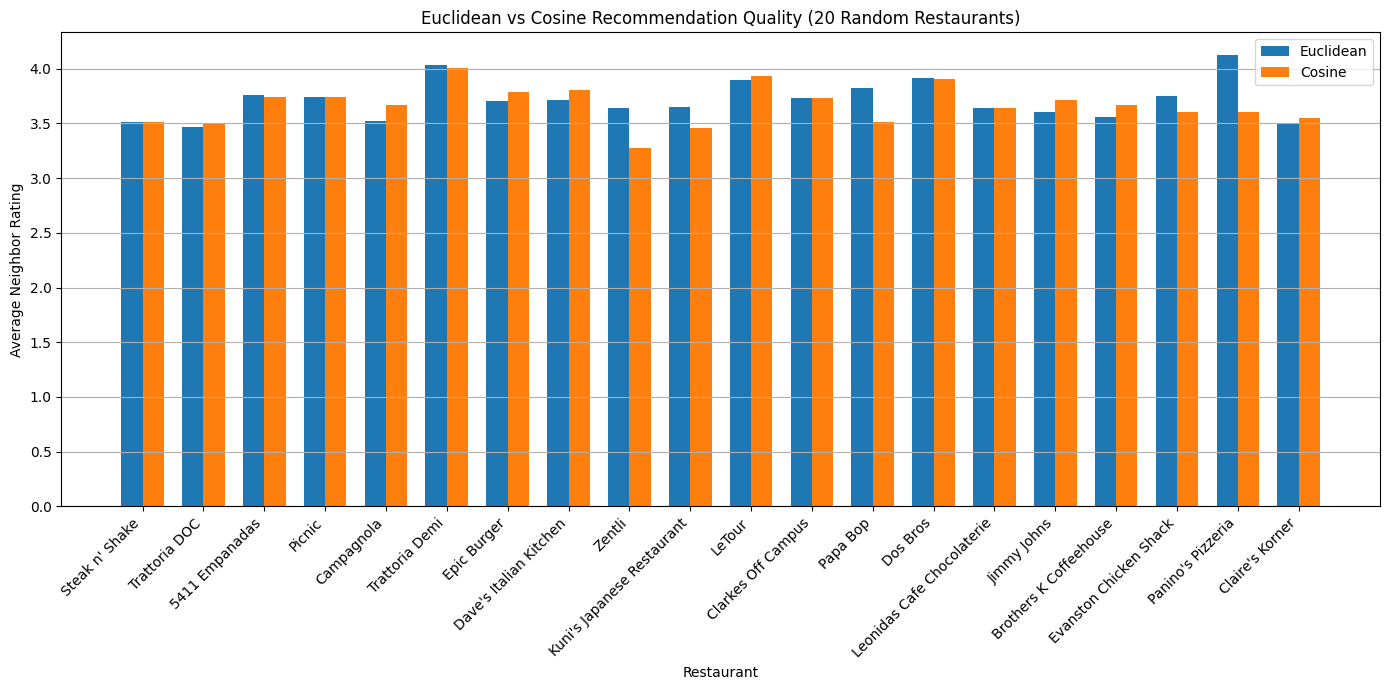

In [24]:
# 1. Remove 'Overall Mean' row
comp_plot = comp[comp['query'] != 'Overall Mean']

# 2. Randomly sample 20 restaurants
sampled = comp_plot.sample(n=20, random_state=42).reset_index(drop=True)

# 3. Set positions for bars
x = np.arange(len(sampled))  # the label locations
width = 0.35  # width of the bars

# 4. Create plot
fig, ax = plt.subplots(figsize=(14, 7))

rects1 = ax.bar(x - width/2, sampled['euclid_avg'], width, label='Euclidean')
rects2 = ax.bar(x + width/2, sampled['cosine_avg'], width, label='Cosine')

# 5. Add labels, title, etc
ax.set_xlabel('Restaurant')
ax.set_ylabel('Average Neighbor Rating')
ax.set_title('Euclidean vs Cosine Recommendation Quality (20 Random Restaurants)')
ax.set_xticks(x)
ax.set_xticklabels(sampled['query'], rotation=45, ha='right')
ax.legend()
ax.grid(True, axis='y')

plt.tight_layout()
plt.show()




Natural Language Analysis Version A

Question 10:

In [28]:
# Ensure both columns exist and handle any missing values
df_res['Brief Description'] = df_res['Brief Description'].fillna('')
df_res['Cuisine']            = df_res['Cuisine'].fillna('')

# Strip a trailing period (if present) and append cuisine
df_res['Augmented Description'] = (
    df_res['Brief Description'].str.rstrip('.')  # drop trailing “.” so we don’t get “..”
    + '. '                                       # add one period + space
    + df_res['Cuisine']
)

# Quick check
print(df_res[['Restaurant Name', 'Augmented Description']].head())


             Restaurant Name  \
0            Tapas Barcelona   
1              Lao Sze Chuan   
2             5411 Empanadas   
3             Hokkaido Ramen   
4  Tomo Japanese Street Food   

                               Augmented Description  
0  Festive, warm space known for Spanish small pl...  
1  Modern Chinese mainstay, known for an extensiv...  
2  Known for Argentinean empanadas & special sauc...  
3  Whimsical ramen bar, known for sushi rolls and...  
4  Japanese street food cafe with mobile app orde...  


Question 12:

In [31]:
# 1. Tokenize Augmented Descriptions into sets of words
def tokenize(text):
    return set(text.lower().split())

# Apply tokenization
df_res['tokenized'] = df_res['Augmented Description'].apply(tokenize)

# 2. Build Jaccard distance function
def jaccard_distance(set1, set2):
    intersection = len(set1.intersection(set2))
    union = len(set1.union(set2))
    if union == 0:
        return 1.0  # completely dissimilar if both empty
    return 1 - intersection / union

# 3. Create empty distance matrix
n = len(df_res)
# Normalize restaurant names to plain ASCII
df_res['Restaurant Name'] = df_res['Restaurant Name'].str.normalize('NFKD').str.encode('ascii', errors='ignore').str.decode('utf-8')
restaurant_names = df_res['Restaurant Name'].values
jaccard_mat = pd.DataFrame(0.0, index=restaurant_names, columns=restaurant_names)

# 4. Fill in the Jaccard distances
for i in range(n):
    for j in range(i, n):
        dist = jaccard_distance(df_res.iloc[i]['tokenized'], df_res.iloc[j]['tokenized'])
        jaccard_mat.iloc[i, j] = dist
        jaccard_mat.iloc[j, i] = dist  # matrix is symmetric

# 5. Report the requested distances
pairs = [
    ('Burger King', "Edzo's Burger Shop"),
    ('Burger King', 'Oceanique'),
    ('Lao Sze Chuan', 'Kabul House')
]

for a, b in pairs:
    dist = jaccard_mat.loc[a, b]
    print(f"Jaccard distance between {a!r} and {b!r}: {dist:.4f}")


Jaccard distance between 'Burger King' and "Edzo's Burger Shop": 0.7727
Jaccard distance between 'Burger King' and 'Oceanique': 0.8846
Jaccard distance between 'Lao Sze Chuan' and 'Kabul House': 0.8182


Question 13:

In [32]:
# ——— Step 1. Helper to get user's favorite restaurant ———
def get_favorite_restaurant(user_name, reviews_df):
    """Returns the name of the favorite restaurant (highest rated) for the given user."""
    user_reviews = reviews_df[reviews_df['Reviewer Name'] == user_name]
    if user_reviews.empty:
        raise ValueError(f"No reviews found for user: {user_name}")
    top_rating = user_reviews['Rating'].max()
    fav_restaurant = user_reviews[user_reviews['Rating'] == top_rating]['Restaurant Name'].iloc[0]
    return fav_restaurant

# ——— Step 2. Recommend based on Jaccard distance ———
def recommend_jaccard(favorite_restaurant, jaccard_matrix):
    """Given a favorite restaurant, recommends the most similar (smallest Jaccard distance) restaurant."""
    # Drop self-match (distance = 0)
    dists = jaccard_matrix.loc[favorite_restaurant].drop(favorite_restaurant)
    # Find the restaurant with the smallest distance
    recommended = dists.idxmin()
    distance = dists.min()
    return recommended, distance

# ——— Step 3. Apply for Calvin Smith and Solomon M ———
users = ['Calvin Smith', 'Solomon M']

for user in users:
    favorite = get_favorite_restaurant(user, df)
    recommendation, jaccard_dist = recommend_jaccard(favorite, jaccard_mat)
    
    print(f"User: {user}")
    print(f"  Favorite restaurant: {favorite}")
    print(f"  Recommended restaurant (by Jaccard distance): {recommendation}")
    print(f"  Jaccard distance between favorite and recommendation: {jaccard_dist:.4f}")
    print()


User: Calvin Smith
  Favorite restaurant: Barn Steakhouse
  Recommended restaurant (by Jaccard distance): Alcove
  Jaccard distance between favorite and recommendation: 0.7407

User: Solomon M
  Favorite restaurant: Hokkaido Ramen
  Recommended restaurant (by Jaccard distance): Tomo Japanese Street Food
  Jaccard distance between favorite and recommendation: 0.7826

